# 01 · Data pre-processing

**CSE274 Unit I.** Types of data, data leakage, missing values and their mechanisms, outliers, categorical encoding, scaling and normalisation, and class imbalance (resampling, SMOTE, algorithmic fixes).

**Dataset:** Kaggle Playground S6E4 *Predicting Irrigation Need*, scored on balanced accuracy. My first submission in April 2026 (a plain XGBoost on one-hot features) scored **0.96021**, rank 3391 of 4315. This project rebuilds that pipeline properly, one syllabus unit at a time, and ends with a new submission in notebook 05.

The competition data is clean: no missing values and no outliers. Real data rarely is, so where a technique needs a problem to fix, the problem is **injected** into a copy and the fix is scored against the known truth.

In [1]:
try:
    import irrigate
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Irrigate
    import irrigate

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split, StratifiedKFold
from irrigate import data, plotting, preprocess
plotting.setup()
rng = np.random.default_rng(0)
CV = StratifiedKFold(5, shuffle=True, random_state=0)

df = data.sample(30_000, seed=0)
y = df[data.TARGET].cat.codes.to_numpy()
print(df.shape)

(29999, 21)


## 1. Data and the pre-processing pipeline

Pre-processing turns raw records into numbers a model can learn from without being misled. The order matters:

1. split off the evaluation data **first**;
2. clean: missing values, outliers, duplicates;
3. encode categories;
4. scale numbers;
5. handle class imbalance;
6. all of it inside a `Pipeline`, so cross-validation refits every step on each training fold.

## 2. Types of data

- **Qualitative (categorical):** *nominal* (soil type, crop, season, irrigation type, water source, region, mulching) and *ordinal* (growth stage: Sowing < Vegetative < Flowering < Harvest).
- **Quantitative (numerical):** all 11 measurements here are *continuous* (pH, moisture, temperature …); a count such as "number of irrigations this season" would be *discrete*.
- **Structured vs unstructured:** this is structured data, a fixed table of columns. Satellite images of the fields or free-text farmer notes would be unstructured and need feature extraction (CNN embeddings, text vectors) before any of this applies.

In [2]:
pd.DataFrame({
    "type": ["quantitative, continuous"] * len(data.NUMERIC) + ["qualitative, ordinal" if c == "Crop_Growth_Stage" else "qualitative, nominal" for c in data.CATEGORICAL],
    "values": [f"{df[c].min():.2f} – {df[c].max():.2f}" for c in data.NUMERIC] + [", ".join(sorted(df[c].unique())) for c in data.CATEGORICAL],
}, index=data.NUMERIC + data.CATEGORICAL)

,type,values
Soil_pH,"quantitative, continuous",4.80 – 8.20
Soil_Moisture,"quantitative, continuous",8.01 – 64.99
Organic_Carbon,"quantitative, continuous",0.30 – 1.60
Electrical_Conductivity,"quantitative, continuous",0.11 – 3.50
Temperature_C,"quantitative, continuous",12.00 – 41.99
Humidity,"quantitative, continuous",25.00 – 94.98
Rainfall_mm,"quantitative, continuous",2.00 – 2499.69
Sunlight_Hours,"quantitative, continuous",4.00 – 10.99
Wind_Speed_kmh,"quantitative, continuous",0.50 – 20.00
Field_Area_hectare,"quantitative, continuous",0.31 – 15.00


## 3. Data leakage

Leakage is information in the training process that won't be available at prediction time. It makes validation scores look great and real scores disappoint. Two common causes, both demonstrated:

**(a) Target leakage:** a feature that is computed *from* the label. Imagine the dataset had a column "water scheduled (mm)" that an irrigation planner filled in *after* deciding the need:

In [3]:
leaky = df.copy()
leaky["Water_Scheduled_mm"] = leaky[data.TARGET].cat.codes * 15 + rng.normal(0, 5, len(leaky))
model = preprocess.pipeline(LogisticRegression(max_iter=2000))
honest = cross_val_score(model, df, y, cv=CV, scoring="balanced_accuracy").mean()
from sklearn.compose import ColumnTransformer
leak_cols = preprocess.column_transformer(numeric=data.NUMERIC + ["Water_Scheduled_mm"])
from sklearn.pipeline import Pipeline
leaked = cross_val_score(Pipeline([("cols", leak_cols), ("model", LogisticRegression(max_iter=2000))]), leaky, y, cv=CV, scoring="balanced_accuracy").mean()
print(f"honest features: {honest:.4f} · with the leaky column: {leaked:.4f}")

honest features: 0.6061 · with the leaky column: 0.9236


A near-perfect score that would collapse in production, because the column doesn't exist before the decision is made.

**(b) Train–test contamination:** fitting a pre-processing step on *all* the data before splitting. The cleanest demonstration uses labels that are pure noise, where the honest answer is chance (33% balanced accuracy for 3 classes). Selecting the 20 "best" of 2,000 random features on all rows, then cross-validating:

In [4]:
from sklearn.feature_selection import SelectKBest, f_classif

noise_X = rng.normal(size=(600, 2000))
noise_y = rng.integers(0, 3, 600)
selected = SelectKBest(f_classif, k=20).fit(noise_X, noise_y).transform(noise_X)      # leak: selection saw every row
wrong = cross_val_score(LogisticRegression(max_iter=2000), selected, noise_y, cv=CV, scoring="balanced_accuracy").mean()
right = cross_val_score(Pipeline([("select", SelectKBest(f_classif, k=20)), ("model", LogisticRegression(max_iter=2000))]),
                        noise_X, noise_y, cv=CV, scoring="balanced_accuracy").mean()
print(f"selection before CV: {wrong:.3f} (looks like signal)   selection inside the pipeline: {right:.3f} (chance is 0.333)")

selection before CV: 0.490 (looks like signal)   selection inside the pipeline: 0.330 (chance is 0.333)


**Prevention:** split first; put every fitted step (imputers, scalers, encoders, selectors, resamplers) inside the pipeline; ask of every feature "would I know this at prediction time?"; be suspicious of scores that are too good.

## 4. Handling missing values

### Mechanisms of missingness
- **MCAR** (missing completely at random): a logger drops readings at random.
- **MAR** (missing at random): missingness depends on *other* observed columns, e.g. moisture probes fail more on hot days.
- **MNAR** (missing not at random): missingness depends on the missing value itself, e.g. probes fail in very dry soil.

20% of soil-moisture values are removed under each mechanism, then each imputation method is scored on how close it gets to the true values (RMSE) and on the downstream model.

In [5]:
def knock_out(frame, mechanism, share=0.2, seed=0):
    r = np.random.default_rng(seed)
    out = frame.copy()
    n = int(share * len(out))
    if mechanism == "MCAR":
        idx = r.choice(len(out), n, replace=False)
    elif mechanism == "MAR":
        p = (out["Temperature_C"].rank(pct=True) ** 3).to_numpy()
        idx = r.choice(len(out), n, replace=False, p=p / p.sum())
    else:  # MNAR
        p = ((1 - out["Soil_Moisture"].rank(pct=True)) ** 3).to_numpy()
        idx = r.choice(len(out), n, replace=False, p=p / p.sum())
    out.iloc[idx, out.columns.get_loc("Soil_Moisture")] = np.nan
    return out

true_moist = df["Soil_Moisture"]
for mech in ["MCAR", "MAR", "MNAR"]:
    m = knock_out(df, mech)
    print(f"{mech}: mean of what's left = {m['Soil_Moisture'].mean():.2f} (true mean {true_moist.mean():.2f})")

MCAR: mean of what's left = 37.21 (true mean 37.27)
MAR: mean of what's left = 37.40 (true mean 37.27)
MNAR: mean of what's left = 41.23 (true mean 37.27)


MNAR is the dangerous one: the values that survive are biased (wetter than reality), and nothing in the remaining data reveals it.

### Handling techniques
Deletion, a constant (mean / median), the most frequent value for categories, k-nearest-neighbours imputation, and iterative (model-based) imputation that predicts each missing column from the others.

In [6]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer

num = data.NUMERIC
imputers = {
    "mean": SimpleImputer(strategy="mean"),
    "median": SimpleImputer(strategy="median"),
    "k-NN (k=10)": KNNImputer(n_neighbors=10),
    "iterative": IterativeImputer(random_state=0, max_iter=10),
}
rows = []
for mech in ["MCAR", "MAR", "MNAR"]:
    m = knock_out(df, mech)
    miss = m["Soil_Moisture"].isna().to_numpy()
    for name, imp in imputers.items():
        filled = pd.DataFrame(imp.fit_transform(m[num]), columns=num)
        rmse = np.sqrt(np.mean((filled.loc[miss, "Soil_Moisture"].to_numpy() - true_moist.to_numpy()[miss]) ** 2))
        rows.append({"mechanism": mech, "imputer": name, "RMSE on the missing values": rmse,
                     "mean after imputing": filled["Soil_Moisture"].mean()})
    kept = m.dropna()
    rows.append({"mechanism": mech, "imputer": "drop rows", "RMSE on the missing values": np.nan,
                 "mean after imputing": kept["Soil_Moisture"].mean()})
imp_table = pd.DataFrame(rows)
imp_table.pivot(index="imputer", columns="mechanism", values="RMSE on the missing values").round(2)

mechanism,MAR,MCAR,MNAR
imputer,,,
drop rows,NaN,NaN,NaN
iterative,16.34,16.42,22.13
k-NN (k=10),17.05,16.93,22.21
mean,16.41,16.46,22.21
median,16.43,16.46,23.74


None of the imputers beats the mean by much here, because soil moisture is independent of the other features (notebook 03 of CSE273 found every VIF ≈ 1): there is nothing for k-NN or the iterative imputer to learn from. On correlated data they would win clearly. Under MNAR every method is worse, since the information about *which* values went missing is in the value itself.

One practical fix keeps that information: add a **missing indicator** column, so the model can learn "a missing moisture reading means dry soil".

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier

m = knock_out(df, "MNAR")
base_cols = preprocess.column_transformer()
res = {}
for name, imp in [("median, no indicator", SimpleImputer(strategy="median")), ("median + missing indicator", SimpleImputer(strategy="median", add_indicator=True))]:
    cols = ColumnTransformer([("num", imp, num), ("rest", base_cols.transformers[1][1], preprocess.NOMINAL),
                              ("stage", base_cols.transformers[2][1], ["Crop_Growth_Stage"])])
    pipe = Pipeline([("cols", cols), ("model", HistGradientBoostingClassifier(random_state=0))])
    res[name] = cross_val_score(pipe, m, y, cv=CV, scoring="balanced_accuracy").mean()
res["no values missing (upper bound)"] = cross_val_score(preprocess.pipeline(HistGradientBoostingClassifier(random_state=0), scale=None), df, y, cv=CV, scoring="balanced_accuracy").mean()
pd.Series(res, name="CV balanced accuracy").round(4)

median, no indicator               0.9089
median + missing indicator         0.9124
no values missing (upper bound)    0.9493
Name: CV balanced accuracy, dtype: float64

## 5. Outlier handling

### Detection methods
The competition data has none, so 60 realistic sensor faults are injected into a copy. Four detectors are compared: the IQR rule and z-scores (one feature at a time), and two multivariate ones, Isolation Forest and the Local Outlier Factor, which can catch values that are only strange *in combination*.

In [8]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

faulty = df[num].copy().reset_index(drop=True)
bad = rng.choice(len(faulty), 60, replace=False)
faulty.loc[bad[:20], "Soil_Moisture"] = rng.uniform(150, 400, 20)                   # broken probe
faulty.loc[bad[20:40], "Temperature_C"] = faulty.loc[bad[20:40], "Temperature_C"] * 9 / 5 + 32  # Fahrenheit
faulty.loc[bad[40:], ["Humidity", "Rainfall_mm"]] = [[99.0, 2.0]] * 20              # saturated air, no rain: impossible together
truth = np.zeros(len(faulty), bool)
truth[bad] = True

kind = np.full(len(faulty), "", dtype=object)
kind[bad[:20]], kind[bad[20:40]], kind[bad[40:]] = "broken probe", "Fahrenheit", "impossible combination"

def report(flags, name):
    row = {"detector": name, "faults caught": f"{(flags & truth).sum()} / 60", "false alarms": int((flags & ~truth).sum())}
    for k in ["broken probe", "Fahrenheit", "impossible combination"]:
        row[k] = f"{(flags & (kind == k)).sum()} / 20"
    return row

q1, q3 = faulty.quantile(0.25), faulty.quantile(0.75)
iqr_flag = ((faulty < q1 - 1.5 * (q3 - q1)) | (faulty > q3 + 1.5 * (q3 - q1))).any(axis=1).to_numpy()
z_flag = (((faulty - faulty.mean()) / faulty.std()).abs() > 3).any(axis=1).to_numpy()
zs = (faulty - faulty.median()) / (q3 - q1)
iso_flag = IsolationForest(contamination=60 / len(faulty), random_state=0).fit_predict(zs) == -1
lof_flag = LocalOutlierFactor(n_neighbors=35, contamination=60 / len(faulty)).fit_predict(zs) == -1
pd.DataFrame([report(iqr_flag, "IQR rule"), report(z_flag, "|z| > 3"), report(iso_flag, "Isolation Forest"), report(lof_flag, "Local Outlier Factor")])

,detector,faults caught,false alarms,broken probe,Fahrenheit,impossible combination
0,IQR rule,39 / 60,0,20 / 20,19 / 20,0 / 20
1,|z| > 3,40 / 60,0,20 / 20,20 / 20,0 / 20
2,Isolation Forest,1 / 60,59,0 / 20,0 / 20,1 / 20
3,Local Outlier Factor,43 / 60,17,20 / 20,20 / 20,3 / 20


The single-feature rules catch every broken probe and most Fahrenheit readings, but none of the "99% humidity with 2 mm of rain" rows: each of those values is normal on its own. The Local Outlier Factor, which compares each field's local density with its neighbours', catches all 40 probe and Fahrenheit faults too, but only 3 of the 20 impossible combinations. Those remain the hardest case for every detector here: 99% humidity and 2 mm of rain are each inside the normal range, and in 11 dimensions the pair is only a small step away from ordinary fields. A rule written from domain knowledge ("saturated air with almost no rain is impossible") would catch all of them.

Isolation Forest does badly here, and the reason is worth knowing. Each of its splits picks a random feature and a random cut. With 11 flat, uniform-looking features, a fault in a single column is only isolated when a tree happens to split on that column, while ordinary fields at the edges of the uniform ranges get isolated just as quickly. It works best when anomalies differ from normal data in many features at once, which is not the case for these faults.

### Treatment methods
Remove the row, **cap** (winsorise) to a percentile, transform (log / Box-Cox for skewed features), or treat the value as missing and impute it. Capping the broken probe readings at the 1st–99th percentiles of the clean data:

before: max 388.7, mean 37.43
capped: max 64.6, mean 37.29 (clean mean 37.27)


/var/folders/_w/p89dnxrd7tl7clzwytpbg6th0000gn/T/ipykernel_89224/3372517243.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot([faulty["Soil_Moisture"]], vert=False)
/var/folders/_w/p89dnxrd7tl7clzwytpbg6th0000gn/T/ipykernel_89224/3372517243.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot([capped], vert=False)


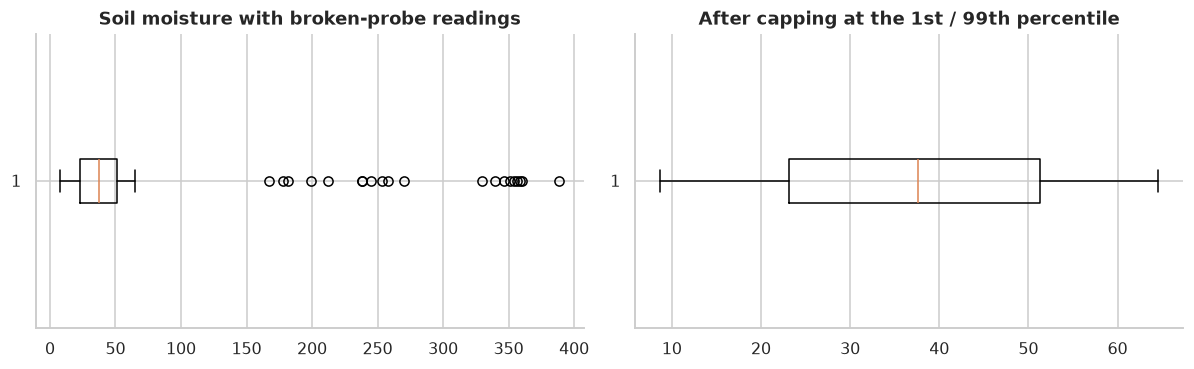

In [9]:
lo, hi = df["Soil_Moisture"].quantile([0.01, 0.99])
capped = faulty["Soil_Moisture"].clip(lo, hi)
print(f"before: max {faulty['Soil_Moisture'].max():.1f}, mean {faulty['Soil_Moisture'].mean():.2f}")
print(f"capped: max {capped.max():.1f}, mean {capped.mean():.2f} (clean mean {df['Soil_Moisture'].mean():.2f})")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].boxplot([faulty["Soil_Moisture"]], vert=False)
axes[0].set_title("Soil moisture with broken-probe readings")
axes[1].boxplot([capped], vert=False)
axes[1].set_title("After capping at the 1st / 99th percentile")
fig.tight_layout()
plotting.save("i01-outliers")
plt.show()

## 6. Handling categorical data

1. **One-hot encoding** for nominal data: one 0/1 column per category, so no fake order is introduced.
2. **Label (ordinal) encoding** for ordinal data: growth stage → 0, 1, 2, 3 keeps its natural order.
3. **Frequency / count encoding:** replace a category by how common it is; compact when there are hundreds of categories.

In [10]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from irrigate.features import FrequencyEncoder

example = df[["Crop_Type", "Crop_Growth_Stage"]].head(6)
onehot = pd.DataFrame(OneHotEncoder(sparse_output=False).fit(df[["Crop_Type"]]).transform(example[["Crop_Type"]]),
                      columns=[f"Crop={c}" for c in sorted(df["Crop_Type"].unique())], index=example.index)
ordinal = pd.Series(OrdinalEncoder(categories=[preprocess.STAGE_ORDER]).fit_transform(example[["Crop_Growth_Stage"]]).ravel(), index=example.index, name="stage code")
freq = pd.Series(FrequencyEncoder().fit(df[["Crop_Type"]]).transform(example[["Crop_Type"]]).ravel(), index=example.index, name="crop frequency")
pd.concat([example, ordinal, freq, onehot.astype(int)], axis=1)

,Crop_Type,Crop_Growth_Stage,stage code,crop frequency,Crop=Cotton,Crop=Maize,Crop=Potato,Crop=Rice,Crop=Sugarcane,Crop=Wheat
0,Cotton,Flowering,2.0,0.167139,1,0,0,0,0,0
1,Rice,Vegetative,1.0,0.169406,0,0,0,1,0,0
2,Maize,Flowering,2.0,0.164005,0,1,0,0,0,0
3,Wheat,Flowering,2.0,0.165506,0,0,0,0,0,1
4,Cotton,Harvest,3.0,0.167139,1,0,0,0,0,0
5,Maize,Flowering,2.0,0.164005,0,1,0,0,0,0


In [11]:
def score_encoding(name, cats):
    cols = ColumnTransformer([("num", "passthrough", num), ("cat", cats, data.CATEGORICAL)])
    pipe = Pipeline([("cols", cols), ("model", HistGradientBoostingClassifier(random_state=0))])
    width = cols.fit_transform(df).shape[1]
    return {"encoding": name, "columns": width, "CV balanced accuracy": cross_val_score(pipe, df, y, cv=CV, scoring="balanced_accuracy").mean()}

pd.DataFrame([
    score_encoding("one-hot", OneHotEncoder(handle_unknown="ignore")),
    score_encoding("ordinal codes for every column", OrdinalEncoder()),
    score_encoding("frequency", FrequencyEncoder()),
]).round(4)

,encoding,columns,CV balanced accuracy
0,one-hot,43,0.9494
1,ordinal codes for every column,19,0.9492
2,frequency,19,0.9480


With a tree model all three work almost equally well; one-hot is the safe default for nominal columns in linear models, where an arbitrary order (Clay = 0, Loamy = 1 …) would be read as a quantity. Frequency encoding is slightly behind: every crop appears in about 1/6 of the fields (0.164–0.169), so the encoding makes different crops look nearly identical. It shines when category frequencies differ a lot, or when there are thousands of categories.

## 7. Scaling and normalisation

- **Standardisation (z-score):** (x − mean) / sd → mean 0, sd 1. Default for linear models, SVMs, PCA.
- **Normalisation (min-max):** (x − min) / (max − min) → [0, 1]. Useful when a bounded range is needed (neural nets, distance-based methods on features with hard limits).

Scaling matters for anything that uses distances or gradient steps, and not at all for trees, which only compare values within one feature:

In [12]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

rows = []
for model_name, model in [("k-NN (k=15)", KNeighborsClassifier(15)), ("logistic regression", LogisticRegression(max_iter=3000)),
                          ("decision tree", DecisionTreeClassifier(max_depth=10, random_state=0))]:
    for scale in [None, "standard", "minmax"]:
        sc = cross_val_score(preprocess.pipeline(model, scale=scale), df, y, cv=CV, scoring="balanced_accuracy").mean()
        rows.append({"model": model_name, "scaling": scale or "none", "CV balanced accuracy": sc})
scaling = pd.DataFrame(rows).pivot(index="model", columns="scaling", values="CV balanced accuracy")
scaling.round(4)

/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/Users/lukshyasupyal/.venvs/ml/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


scaling,minmax,none,standard
model,,,
decision tree,0.9438,0.9438,0.9438
k-NN (k=15),0.4940,0.5702,0.6316
logistic regression,0.6017,0.6004,0.6061


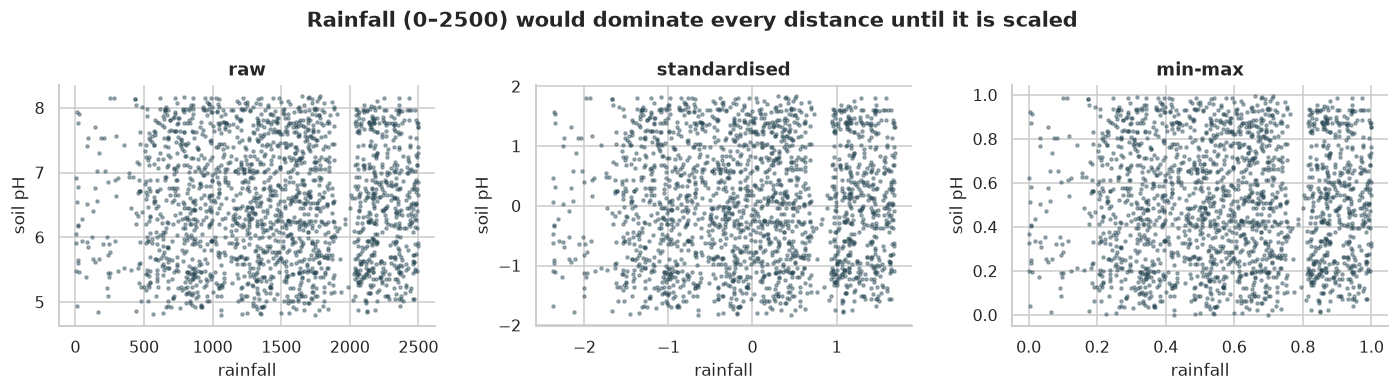

In [13]:
raw = df[["Rainfall_mm", "Soil_pH"]]
from sklearn.preprocessing import StandardScaler, MinMaxScaler
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, vals) in zip(axes, [("raw", raw.to_numpy()), ("standardised", StandardScaler().fit_transform(raw)), ("min-max", MinMaxScaler().fit_transform(raw))]):
    ax.scatter(vals[:2000, 0], vals[:2000, 1], s=4, alpha=0.4, color=plotting.ACCENT)
    ax.set(title=name, xlabel="rainfall", ylabel="soil pH")
fig.suptitle("Rainfall (0–2500) would dominate every distance until it is scaled", fontweight="bold")
fig.tight_layout()
plotting.save("i01-scaling")
plt.show()

Trees don't care at all. k-NN cares a lot, and not in the obvious direction. Unscaled, its distances are almost entirely rainfall (range 2,500), which is a weak feature. Min-max scaling is even *worse*: it squeezes the 11 numeric features into [0, 1], the same range as the 35 one-hot category columns, and those mostly irrelevant columns then dominate the distances. Standardising gives the numeric features a spread of 1, larger than a 0/1 column's, and does best. The scaler has to suit the model *and* the other columns.

## 8. Class imbalance handling

High need is **3.3%** of fields. A model trained to maximise accuracy can largely ignore it, but balanced accuracy gives High a third of the score. This is exactly why my first submission (plain XGBoost, argmax predictions) stopped at 0.960.

### Techniques
1. **Resampling:** random under-sampling of the majority classes, or random over-sampling of the minority.
2. **SMOTE:** creates *synthetic* minority examples by interpolating between a minority point and one of its minority neighbours.
3. **Algorithmic approaches:** class weights in the loss, or moving the decision threshold.

All are compared with the same gradient-boosting model, resampling **inside** the cross-validation (imblearn's pipeline), because resampling before the split is leakage.

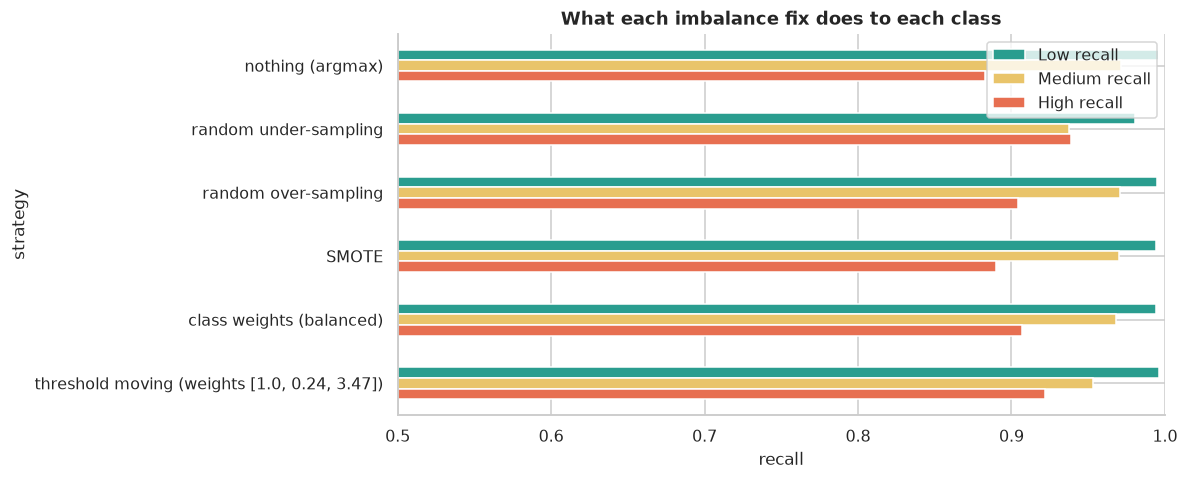

,balanced accuracy,Low recall,Medium recall,High recall
strategy,,,,
nothing (argmax),0.9499,0.9952,0.9715,0.883
random under-sampling,0.9523,0.9804,0.9375,0.939
random over-sampling,0.9566,0.9948,0.9708,0.904
SMOTE,0.9513,0.9940,0.9700,0.890
class weights (balanced),0.9563,0.9942,0.9678,0.907
"threshold moving (weights [1.0, 0.24, 3.47])",0.9571,0.9963,0.9531,0.922


In [14]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import cross_val_predict
from irrigate import decision

hgb = lambda **kw: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=0, **kw)
cols = preprocess.column_transformer()
strategies = {
    "nothing (argmax)": ImbPipeline([("cols", cols), ("model", hgb())]),
    "random under-sampling": ImbPipeline([("cols", cols), ("rs", RandomUnderSampler(random_state=0)), ("model", hgb())]),
    "random over-sampling": ImbPipeline([("cols", cols), ("rs", RandomOverSampler(random_state=0)), ("model", hgb())]),
    "SMOTE": ImbPipeline([("cols", cols), ("rs", SMOTE(random_state=0)), ("model", hgb())]),
    "class weights (balanced)": ImbPipeline([("cols", cols), ("model", hgb(class_weight="balanced"))]),
}
rows = []
probas = {}
for name, pipe in strategies.items():
    proba = cross_val_predict(pipe, df, y, cv=CV, method="predict_proba")
    probas[name] = proba
    pred = proba.argmax(1)
    rec = [np.mean(pred[y == k] == k) for k in range(3)]
    rows.append({"strategy": name, "balanced accuracy": balanced_accuracy_score(y, pred), "Low recall": rec[0], "Medium recall": rec[1], "High recall": rec[2]})

# threshold moving: tune class weights on the out-of-fold probabilities of the plain model
w, _ = decision.search_weights(probas["nothing (argmax)"], y)
pred = decision.decide(probas["nothing (argmax)"], w)
rec = [np.mean(pred[y == k] == k) for k in range(3)]
rows.append({"strategy": f"threshold moving (weights {np.round(w, 2).tolist()})", "balanced accuracy": balanced_accuracy_score(y, pred),
             "Low recall": rec[0], "Medium recall": rec[1], "High recall": rec[2]})
imb = pd.DataFrame(rows).set_index("strategy")

ax = imb[["Low recall", "Medium recall", "High recall"]].plot.barh(color=[plotting.CLASS_COLORS[c] for c in data.CLASSES], figsize=(9, 4.5))
ax.set(xlabel="recall", title="What each imbalance fix does to each class", xlim=(0.5, 1.0))
ax.invert_yaxis()
plotting.save("i01-imbalance")
plt.show()
imb.round(4)

Every fix trades a little Low/Medium recall for much better High recall, and balanced accuracy rewards that trade. The threshold weights above were tuned on the same out-of-fold predictions they are scored on, so that row is slightly optimistic; notebook 05 tunes them on one set of folds and checks them on held-out data before submitting.

| Syllabus topic | Where |
|---|---|
| Introduction, key pre-processing steps | 1 |
| Types of data (qualitative, quantitative, structured vs unstructured) | 2 |
| Data leakage: causes and prevention | 3 |
| Missing values: mechanisms and techniques | 4 |
| Outliers: detection and treatment | 5 |
| Categorical data: one-hot, label, frequency encoding | 6 |
| Standardisation and min-max normalisation | 7 |
| Class imbalance: resampling, SMOTE, algorithmic approaches | 8 |